# **SETUP INICIAL**

## 1. IMPORTS Y CONFIGURACIÓN

In [ ]:
!pip install -q pyspark cassandra-driver astrapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.4/374.4 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 333.5/333.5 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 14.3 MB/s eta 0:00:00


In [ ]:
import os
import json
import threading
import time
import pandas as pd
from datetime import datetime, timezone, date, timedelta

from astrapy import DataAPIClient
from cassandra.cluster import Cluster
from cassandra.auth import PlainTextAuthProvider
from cassandra.query import BatchStatement, ConsistencyLevel
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.window import Window

In [ ]:
# Conectar Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. RUTAS DEL DATA LAKE  (HDFS simulado)

In [ ]:
DATALAKE_BASE = "/content/drive/MyDrive/cloud-provider-data-platform/datalake"

PATHS = {
    "landing":      f"{DATALAKE_BASE}/landing",
    "bronze":       f"{DATALAKE_BASE}/bronze",
    "silver":       f"{DATALAKE_BASE}/silver",
    "gold":         f"{DATALAKE_BASE}/gold",
    "checkpoints":  f"{DATALAKE_BASE}/checkpoints",
    "quarantine":   f"{DATALAKE_BASE}/quarantine"
}

# Crear estructura de carpetas
for key, path in PATHS.items():
    os.makedirs(path, exist_ok=True)
    print(f"📂 Ruta verificada: {path}")

📂 Ruta verificada: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/landing
📂 Ruta verificada: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/bronze
📂 Ruta verificada: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/silver
📂 Ruta verificada: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/gold
📂 Ruta verificada: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/checkpoints
📂 Ruta verificada: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/quarantine


## 3. SPARK SESSION

In [ ]:
spark = (SparkSession.builder
    .appName("CloudAnalytics_Lambda_Project")
    .config("spark.sql.streaming.schemaInference", "true")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.driver.memory", "4g")
    .getOrCreate())

spark.sparkContext.setLogLevel("WARN")
print(f"✔ Spark iniciado: {spark.version}")


✔ Spark iniciado: 4.0.1


## 3. ASTRA DB

- Conexión a Cassandra y creación de colección para la data streaming (speed)

In [ ]:
## 3. ASTRA DB
# Snippet generado por DataStax (Connect) — reemplazá con tu propio token
ASTRA_TOKEN = "TU_TOKEN_AQUI"

# - Conexión a Cassandra y creación de colección para la data streaming (speed)
def get_astra_db():
    return DataAPIClient(ASTRA_TOKEN).get_database_by_api_endpoint(
        "https://0f31cfd5-430c-4598-8a6a-8f91ebc46db7-us-east-2.apps.astra.datastax.com",
        keyspace="cloud_provider"
    )

try:
    db = get_astra_db()
    if "speed_usage_events" not in db.list_collections():
      db.create_collection("speed_usage_events")
      print("✔ Colección creada: speed_usage_events")
except Exception as e:
    print(f"✖️ Error inicializando Astra: {e}")



✔ Colección creada: speed_usage_events


- CONFIGURACIÓN DE SESIÓN CQL (cassandra-driver)

In [ ]:
ASTRA_TOKEN = "TU_TOKEN_AQUI"
BUNDLE_PATH = "/content/drive/MyDrive/cloud-provider-data-platform/datalake/secure-connect-db-cloudprovider.zip"

# ---------------------------------------------------------

if not os.path.exists(BUNDLE_PATH):
    print(f"ALERTA: No se encontró el bundle en: {BUNDLE_PATH}")
    print("→ Por favor sube el archivo .zip de conexión a Colab y actualiza la variable BUNDLE_PATH.")
else:
    try:
        cloud_config = {
            'secure_connect_bundle': BUNDLE_PATH
        }
        auth_provider = PlainTextAuthProvider('token', ASTRA_TOKEN)
        cluster = Cluster(cloud=cloud_config, auth_provider=auth_provider)
        session = cluster.connect()

        session.set_keyspace('cloud_provider')

        print("✔ Session CQL inicializada correctamente.")

    except Exception as e:
        print(f"✖️ Error conectando: {e}")

✔ Session CQL inicializada correctamente.


## 4. Esquemas (inferidos)

In [ ]:
batch_files = [
    "customers_orgs.csv",
    "users.csv",
    "resources.csv",
    "support_tickets.csv",
    "billing_monthly.csv",
    "nps_surveys.csv",
    "marketing_touches.csv"
]

for filename in batch_files:
    print(f"\n====== {filename} ======")
    path = f"{PATHS['landing']}/{filename}"

    df = (
        spark.read.format("csv")
            .option("header", True)
            .option("inferSchema", True)
            .load(path)
    )

    df.show(5, truncate=False)
    df.printSchema()



====== customers_orgs.csv ======
+------------+---------------+-------------+----------+---------+-------------+-----------+---------+---------------+----------------+---------+
|org_id      |org_name       |industry     |hq_region |plan_tier|is_enterprise|signup_date|sales_rep|lifecycle_stage|marketing_source|nps_score|
+------------+---------------+-------------+----------+---------+-------------+-----------+---------+---------------+----------------+---------+
|org_xaji0y6d|Nimbus Labs 0  |Education    |sa-east   |standard |true         |2025-05-26 |rep_c    |churned        |partner         |NULL     |
|org_pbhsahxt|Nova Tech 1    |Education    |us-east   |standard |false        |2025-06-16 |rep_d    |lead           |event           |-3.0     |
|org_hv3a3zmf|Gamma Data 2   |Media        |eu-central|pro      |true         |2025-05-12 |rep_c    |active         |organic         |4.0      |
|org_8mdd4v30|Apex Data 3    |Manufacturing|sa-east   |standard |false        |2025-05-30 |rep_b

## 5. Definición de esquemas explícitos

In [ ]:
# SCHEMAS BATCH
schema_customers = StructType([
    StructField("org_id", StringType(), True),
    StructField("org_name", StringType(), True),
    StructField("industry", StringType(), True),
    StructField("hq_region", StringType(), True),
    StructField("plan_tier", StringType(), True),
    StructField("is_enterprise", BooleanType(), True),
    StructField("signup_date", DateType(), True),
    StructField("sales_rep", StringType(), True),
    StructField("lifecycle_stage", StringType(), True),
    StructField("marketing_source", StringType(), True),
    StructField("nps_score", DoubleType(), True)
])

schema_users = StructType([
    StructField("user_id", StringType(), True),
    StructField("org_id", StringType(), True),
    StructField("email", StringType(), True),
    StructField("role", StringType(), True),
    StructField("active", BooleanType(), True),
    StructField("created_at", DateType(), True),
    StructField("last_login", DateType(), True)
])

schema_resources = StructType([
    StructField("resource_id", StringType(), True),
    StructField("org_id", StringType(), True),
    StructField("service", StringType(), True),
    StructField("region", StringType(), True),
    StructField("created_at", DateType(), True),
    StructField("state", StringType(), True),
    StructField("tags_json", StringType(), True)
])

schema_support = StructType([
    StructField("ticket_id", StringType(), True),
    StructField("org_id", StringType(), True),
    StructField("category", StringType(), True),
    StructField("severity", StringType(), True),
    StructField("created_at", DateType(), True),
    StructField("resolved_at", DateType(), True),
    StructField("csat", DoubleType(), True),
    StructField("sla_breached", BooleanType(), True)
])

schema_billing = StructType([
    StructField("invoice_id", StringType(), True),
    StructField("org_id", StringType(), True),
    StructField("month", DateType(), True),
    StructField("subtotal", DoubleType(), True),
    StructField("credits", DoubleType(), True),
    StructField("taxes", DoubleType(), True),
    StructField("currency", StringType(), True),
    StructField("exchange_rate_to_usd", DoubleType(), True),
])

schema_nps = StructType([
    StructField("org_id", StringType(), True),
    StructField("survey_date", DateType(), True),
    StructField("nps_score", DoubleType(), True),
    StructField("comment", StringType(), True)
])

schema_marketing = StructType([
    StructField("touch_id", StringType(), True),
    StructField("org_id", StringType(), True),
    StructField("campaign", StringType(), True),
    StructField("channel", StringType(), True),
    StructField("timestamp", DateType(), True),
    StructField("clicked", BooleanType(), True),
    StructField("converted", BooleanType(), True),
])

# -------------------------------------------------

batch_schemas = {
    "customers_orgs.csv": schema_customers,
    "users.csv": schema_users,
    "resources.csv": schema_resources,
    "support_tickets.csv": schema_support,
    "billing_monthly.csv": schema_billing,
    "nps_surveys.csv": schema_nps,
    "marketing_touches.csv": schema_marketing
}


In [ ]:
#streaming schema

schema_usage_events = StructType([
    StructField("event_id", StringType(), True),
    StructField("timestamp", TimestampType(), True),
    StructField("org_id", StringType(), True),
    StructField("resource_id", StringType(), True),
    StructField("service", StringType(), True),
    StructField("region", StringType(), True),
    StructField("metric", StringType(), True),
    StructField("value", DoubleType(), True),
    StructField("unit", StringType(), True),
    StructField("cost_usd_increment", DoubleType(), True),
    StructField("schema_version", IntegerType(), True),
    # Campos de schema version 2 (pueden venir nulos)
    StructField("carbon_kg", DoubleType(), True),
    StructField("genai_tokens", DoubleType(), True)
])


#---

# ***CONTEO ANTES DE PIPLINE (para verificar idempotencia)***




In [ ]:
tables = [
    "gold_daily_usage_by_org_service",
    "gold_daily_cost_by_org",
    "gold_monthly_revenue",
    "gold_support_daily"
]

print("=== ESTADO INICIAL EN ASTRA ===\n")

for t in tables:
    count = session.execute(f"SELECT COUNT(*) FROM cloud_provider.{t}").one()[0]
    head = session.execute(f"SELECT * FROM cloud_provider.{t} LIMIT 3").all()

    print(f"\n▶ Tabla: {t}")
    print(f"   Count: {count}")
    print(f"   Head (5 filas):")
    for row in head:
        print("     ", row)


# ---

# **INGESTA LANDING → BRONZE**

- **LA DATA ESTÁ CRUDA EN LANDING**

## PARTE A - INGESTA STREAMING LANDING → BRONZE

In [ ]:
# Función ingesta streaming a bronze
def run_ingest_stream_thread():
    print(">>> [Thread] Iniciando Ingesta Streaming Landing → Bronze...")

    # 1) Lectura JSONL desde Landing
    raw_stream = (
        spark.readStream
        .format("json")
        .schema(schema_usage_events)
        .option("maxFilesPerTrigger", 10)
        .option("cleanSource", "archive")
        .option("sourceArchiveDir", f"{PATHS['landing']}/archive")
        .load(f"{PATHS['landing']}/usage_events_stream")
    )

    # 2) Limpieza y normalización
    processed = (
        raw_stream
        .withWatermark("timestamp", "2 minutes")
        .dropDuplicates(["event_id"])
        # Generar ingest_ts con timezone UTC en ISO8601
        .withColumn("ingest_ts", F.date_format(F.current_timestamp(), "yyyy-MM-dd'T'HH:mm:ssXXX"))
        .withColumn("source_file", input_file_name())
        .withColumn(
            "row_valid",
            when(col("event_id").isNull() | col("org_id").isNull(), False).otherwise(True)
        )
    )

    # 3) Escrbir Bronze particionado por fecha de uso
    q1 = (
        processed.filter("row_valid = true")
        .withColumn("usage_date", F.to_date("timestamp"))
        .writeStream
        .format("parquet")
        .partitionBy("usage_date")
        .option("path", f"{PATHS['bronze']}/usage_events")
        .option("checkpointLocation", f"{PATHS['checkpoints']}/ingest_bronze")
        .outputMode("append")
        .trigger(processingTime="5 seconds")
        .start()
    )

    # 4) Escrbir Quarantine
    q2 = (
        processed.filter("row_valid = false")
        .writeStream
        .format("parquet")
        .option("path", f"{PATHS['quarantine']}/usage_events")
        .option("checkpointLocation", f"{PATHS['checkpoints']}/ingest_quarantine")
        .outputMode("append")
        .trigger(processingTime="5 seconds")
        .start()
    )

    spark.streams.awaitAnyTermination()


# Lanzar thread en backgropund
t_ingest = threading.Thread(target=run_ingest_stream_thread, daemon=True)
t_ingest.start()

print("✔ Ingesta Streaming corriendo en background. Viendo landing/usage_events_stream/")


>>> [Thread] Iniciando Ingesta Streaming Landing → Bronze...
✔ Ingesta Streaming corriendo en background. Viendo landing/usage_events_stream/


## PARTE B - INGESTA BATCH LANDING → BRONZE

In [ ]:
# diccionario de IDs obligatorios
ID_COLUMNS = {
    "customers_orgs.csv": ["org_id"],
    "users.csv": ["user_id", "org_id"],
    "resources.csv": ["resource_id", "org_id"],
    "tickets_support.csv": ["ticket_id", "org_id"],
    "billing_monthly.csv": ["invoice_id", "org_id"],
    "marketing_touches.csv": ["touch_id", "org_id"],
    "nps_surveys.csv": ["org_id"]
}

# Función de ingesta batch desde landing a la capa bronze
def ingest_batch_to_bronze(filename):

    schema = batch_schemas[filename]
    print(f"\n=== Batch Ingest: {filename} ===")

    # 1) Lectura desde landing
    df = (
        spark.read.format("csv")
            .schema(schema)
            .option("header", True)
            .load(f"{PATHS['landing']}/{filename}")
            .withColumn("ingest_ts", current_timestamp())
            .withColumn("source_file", lit(filename))
    )

    # 2) Validación Dinámica
    # Recuperamos las columnas a validar para este archivo específico.
    # Si no está en el dict, devuelve lista vacía []
    required_cols = ID_COLUMNS.get(filename, [])

    # Generamos una expresión dinámica para el mensaje de error.
    # Por cada columna requerida, si es NULL, agregamos texto. concat_ws une los errores con coma.
    error_expr = concat_ws(", ", *[
        when(col(c).isNull(), lit(f"{c} null")).otherwise(lit(None))
        for c in required_cols
    ])

    # Aplicamos la validación
    # Si 'error_reason' queda con texto (string != ""), significa que falló alguna validación.
    df = (
        df.withColumn("error_reason", error_expr)
          .withColumn("row_valid",
                      when(col("error_reason") != "", False).otherwise(True))
          # Ajuste cosmético: si no hay error, ponemos null en error_reason para limpiar
          .withColumn("error_reason",
                      when(col("error_reason") == "", None).otherwise(col("error_reason")))
    )

    # 3) Paths de salida
    bronze_path = f"{PATHS['bronze']}/{filename.replace('.csv','')}"
    quarantine_path = f"{PATHS['quarantine']}/{filename.replace('.csv','')}"

    # 4) Escritura
    print("Total filas en quarantine:", df.filter("row_valid = false").count())

    invalid_df = df.filter("row_valid = false")

    # Solo mostramos si hay errores
    if not invalid_df.rdd.isEmpty():
        print("\n--- FILAS EN QUARANTINE ---")
        invalid_df.select("source_file", "error_reason").show(truncate=False) # Muestro la razón del error
        invalid_df.write.mode("append").parquet(quarantine_path)
        print(f"✔ Quarantine actualizado: {quarantine_path}")
    else:
        print(f"✔ No hay filas inválidas en {filename}, no se crea archivo quarantine.")

    # Bronze siempre se escribe
    df.filter("row_valid = true").write.mode("overwrite").parquet(bronze_path)
    print(f"✔ Bronze actualizado: {bronze_path}")


# Ejecutar función para todos los csv
for filename in batch_schemas.keys():
    ingest_batch_to_bronze(filename)

print("\n>>> ✔ INGESTA BATCH COMPLETADA")


=== Batch Ingest: customers_orgs.csv ===
Total filas en quarantine: 0
✔ No hay filas inválidas en customers_orgs.csv, no se crea archivo quarantine.
✔ Bronze actualizado: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/bronze/customers_orgs

=== Batch Ingest: users.csv ===
Total filas en quarantine: 0
✔ No hay filas inválidas en users.csv, no se crea archivo quarantine.
✔ Bronze actualizado: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/bronze/users

=== Batch Ingest: resources.csv ===
Total filas en quarantine: 0
✔ No hay filas inválidas en resources.csv, no se crea archivo quarantine.
✔ Bronze actualizado: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/bronze/resources

=== Batch Ingest: support_tickets.csv ===
Total filas en quarantine: 0
✔ No hay filas inválidas en support_tickets.csv, no se crea archivo quarantine.
✔ Bronze actualizado: /content/drive/MyDrive/Mineria de Datos II CLZ/datalake/bronze/support_tickets

=== Batch Ingest: billing_monthly.csv 

# **TRANSICIÓN BRONZE → SILVER**

 - **LA DATA ESTÁ EN BRONZE**

  *SILVER BATCH LAYER + STREAM SPEED LAYER → ASTRA*

## PARTE A — STREAMING: SPEED LAYER → ASTRA

In [ ]:
print("=== INICIANDO SPEED LAYER (STREAM → ASTRA) ===")

# =============================================================================
# 1. CONEXIÓN A ASTRA

db = DataAPIClient(
    ASTRA_TOKEN
).get_database_by_api_endpoint(
    "https://0f31cfd5-430c-4598-8a6a-8f91ebc46db7-us-east-2.apps.astra.datastax.com",
    keyspace="cloud_provider"
)

COL_RAW = "speed_usage_events"
if COL_RAW not in db.list_collections():
    db.create_collection(COL_RAW)
col_raw = db.get_collection(COL_RAW)

print(f"Conectado a Astra: {COL_RAW}")

# =============================================================================
# 2. SCHEMAS PARA DIMENSIONES (para DataFrames vacíos)

schema_customers_orgs = StructType([
    StructField("org_id", StringType(), True),
    StructField("org_name", StringType(), True),
    StructField("country", StringType(), True),
    StructField("industry", StringType(), True),
])

schema_resources = StructType([
    StructField("resource_id", StringType(), True),
    StructField("resource_type", StringType(), True),
    StructField("service", StringType(), True),
    StructField("region", StringType(), True),
])

# =============================================================================
# 3. FUNCION INTELIGENTE PARA CARGAR DIMENSIONES
#    - Si existe parquet → lo carga
#    - Si no existe → DataFrame vacío con schema

def safe_load_dim(path, schema):
    try:
        return spark.read.parquet(path)
    except Exception:
        print(f"⚠ Dim no encontrada: {path}. Usando DataFrame vacío con schema.")
        return spark.createDataFrame([], schema)

orgs_silver = safe_load_dim(
    f"{PATHS['silver']}/customers_orgs",
    schema_customers_orgs
).cache()

resources_silver = safe_load_dim(
    f"{PATHS['silver']}/resources",
    schema_resources
).cache()

print("→ Dimensiones cargadas (vacías si batch aún no corrió).")

# =============================================================================
# 4. LECTURA DESDE BRONZE (STREAM)

df_stream = (
    spark.readStream
        .format("parquet")
        .option("maxFilesPerTrigger", 1)
        .load(f"{PATHS['bronze']}/usage_events")
)

# =============================================================================
# 5. CLEAN STREAM

df_stream_clean = (
    df_stream
        .withWatermark("timestamp", "10 minutes")
        .dropDuplicates(["event_id"])
        .withColumn("usage_date", F.to_date("timestamp"))
        .withColumn("value", F.col("value").cast("double"))
        .withColumn("cost_usd_increment", F.col("cost_usd_increment").cast("double"))
        .withColumn("genai_tokens", F.coalesce("genai_tokens", F.lit(0.0)))
        .withColumn("carbon_kg", F.coalesce("carbon_kg", F.lit(0.0)))
        .filter("cost_usd_increment >= -0.01")
)

# =============================================================================
# 6. ENRICH STREAM

df_stream_enriched = (
    df_stream_clean
        .join(F.broadcast(orgs_silver), "org_id", "left")
        .join(F.broadcast(resources_silver), "resource_id", "left")
        .fillna(0)
)

# =============================================================================
# 7. FOREACH BATCH → INSERTAR EN ASTRA

def sanitize_json(v):
    if v is None or (isinstance(v, float) and v != v):  # NaN
        return 0
    return v

def chunked_iterable_from_iterator(it, size=100):
    chunk = []
    for item in it:
        chunk.append(item)
        if len(chunk) >= size:
            yield chunk
            chunk = []
    if chunk:
        yield chunk

def process_batch(df, batch_id):
    # Ver existencia rápida.
    try:
        if df.rdd.isEmpty():
            # no rows
            return
    except Exception:
        # fallback seguro: take(1)
        if len(df.take(1)) == 0:
            return

    print(f"\n[batch {batch_id}] Iniciando procesamiento microbatch...")

    # Usamos toLocalIterator() para iterar sin traer TODO a memoria
    it = df.fillna(0).toLocalIterator()

    inserted = 0
    errors = 0

    for chunk in chunked_iterable_from_iterator(it, size=100):
        for r in chunk:
            try:
                row = r.asDict()
                # sanitize values
                doc = {k: sanitize_json(v) for k, v in row.items()}

                _id = doc.get("event_id") or f"evt_{hash((doc.get('org_id'), doc.get('timestamp')))}"
                doc["_id"] = _id

                # ======= timestamp robust UTC conversion (por errores de ingesta) =======
                ts = row.get("timestamp")
                if ts is None:
                    doc["timestamp"] = None
                else:
                    # ts suele ser datetime naive desde Spark -> forzamos UTC
                    try:
                        # si es string, parsearlo (fallback)
                        if isinstance(ts, str):
                            # intenta parse ISO-like; si falla, dejar como string ISO +Z
                            try:
                                parsed = datetime.fromisoformat(ts)
                                ts = parsed
                            except Exception:
                                # mejor fallback: tratar como naive and replace tz
                                ts = datetime.strptime(ts, "%Y-%m-%d %H:%M:%S")
                        # forzar tz UTC
                        ts = ts.replace(tzinfo=timezone.utc)
                        doc["timestamp"] = ts.isoformat()
                    except Exception:
                        # si todo falla, enviar string con +00:00 para que Astra reciba timezone
                        try:
                            doc["timestamp"] = f"{str(ts)}+00:00"
                        except Exception:
                            doc["timestamp"] = None

                # ======= usage_date (DateType) -> datetime UTC =======
                ud = row.get("usage_date")
                if ud is None:
                    doc["usage_date"] = None
                else:
                    try:
                        # si viene como date/datetime
                        if isinstance(ud, date) and not isinstance(ud, datetime):
                            ud_dt = datetime.combine(ud, datetime.min.time()).replace(tzinfo=timezone.utc)
                        elif isinstance(ud, datetime):
                            ud_dt = ud.replace(tzinfo=timezone.utc)
                        else:
                            # si viene como string
                            ud_dt = datetime.fromisoformat(str(ud)).replace(tzinfo=timezone.utc)
                        doc["usage_date"] = ud_dt.isoformat()
                    except Exception:
                        doc["usage_date"] = f"{str(ud)}+00:00"

                # Upsert a Astra
                col_raw.replace_one({"_id": _id}, doc, upsert=True)
                inserted += 1

            except Exception as e:
                errors += 1
                if errors <= 5:
                    print(f"✖️ Error Astra (fila): {e}")

    print(f"[batch {batch_id}] Speed → Astra: {inserted} eventos, {errors} errores")

# =============================================================================
# 8. EJECUTAR STREAMING

query = (
    df_stream_enriched
        .writeStream
        .foreachBatch(process_batch)
        .option("checkpointLocation", f"{PATHS['checkpoints']}/speed_astra")
        .trigger(processingTime="5 seconds")
        .start()
)

print("→ Speed Layer activo (Astra en tiempo real)")
print(" ...Esperando nuevos eventos desde Bronze...")


=== INICIANDO SPEED LAYER (STREAM → ASTRA) ===
Conectado a Astra: speed_usage_events
→ Dimensiones cargadas (vacías si batch aún no corrió).
→ Speed Layer activo (Astra en tiempo real)
 ...Esperando nuevos eventos desde Bronze...


## PARTE B — SILVER BATCH

In [ ]:
print("=== INICIANDO BATCH SILVER ===")

# =============================================================================
def read_bronze(archivos):
    for name in archivos:
        p = f"{PATHS['bronze']}/{name}"
        if os.path.exists(p):
            df = spark.read.parquet(p)
            print(f"✔ Cargado bronze: {name} ({df.count()} filas)")
            return df

    # Si terminó el for sin retornar nada:
    raise FileNotFoundError(f"No se encontró ninguno de: {archivos}")

# ==========================================================================
# BATCH SILVER
print("\n=== Procesando SILVER Batch ===")

df_orgs_bz = read_bronze(["customers_orgs"])
df_resources_bz = read_bronze(["resources"])
df_billing_bz = read_bronze(["billing_monthly"])
df_tickets_bz = read_bronze(["support_tickets"])
df_usage_events_bz = read_bronze(["usage_events"])

# Evolución del schema
for c, default in {"genai_tokens": 0.0, "carbon_kg": 0.0}.items():
    if c not in df_usage_events_bz.columns:
        df_usage_events_bz = df_usage_events_bz.withColumn(c, F.lit(default))


# ==========================================================================
# DIM ORGS (Silver)

orgs_silver = (
    df_orgs_bz
        .fillna({"industry": "UNKNOWN", "nps_score": 0})
        .select("org_id", "org_name", "industry", "plan_tier", "nps_score")
)
orgs_silver.write.mode("overwrite").parquet(f"{PATHS['silver']}/customers_orgs")
print("✔ Orgs Silver")

# ==========================================================================
# DIM RESOURCES (Silver)

resources_silver = (
    df_resources_bz
        .select(
            "resource_id",
            F.lower("service").alias("resource_service"),
            F.col("region").alias("resource_region"),
            F.col("state").alias("resource_state")
        )
)
resources_silver.write.mode("overwrite").parquet(f"{PATHS['silver']}/resources")
print("✔ Resources Silver")

# ==========================================================================
# INICIO DE MEDICIÓN: Transformación pesada (Joins + Window)
start_silver_time = time.time()


# USAGE EVENTS SILVER (Batch) - CON REGLAS DE CALIDAD

df_usage_silver = (
    df_usage_events_bz
        .withColumn("usage_date", F.to_date("timestamp"))
        .withColumn("value", F.col("value").cast("double"))
        .withColumn("cost_usd_increment", F.col("cost_usd_increment").cast("double"))
        .join(orgs_silver, "org_id", "left")
        .join(resources_silver, "resource_id", "left")
        .fillna(0)
)

# ==========================================================================
# REGLAS DE CALIDAD
# Regla 1: event_id no nulo
df_usage_silver = df_usage_silver.withColumn(
    "valid_event_id",
    F.col("event_id").isNotNull()
)

# Regla 2: cost >= -0.01 (permitir pequeños ajustes negativos)
df_usage_silver = df_usage_silver.withColumn(
    "valid_cost",
    F.col("cost_usd_increment") >= -0.01
)


# REGLA 3: unit no nulo cuando value no nulo
df_usage_silver = df_usage_silver.withColumn(
    "valid_unit",
    F.when(F.col("value").isNotNull(), F.col("unit").isNotNull())
     .otherwise(True)  # Si value es null, no validamos unit
)

# Regla 4: Anomalías Z-score
w = Window.partitionBy("org_id")
df_usage_silver = (
    df_usage_silver
        .withColumn(
            "z_cost",
            (F.col("cost_usd_increment") - F.avg("cost_usd_increment").over(w)) /
            (F.stddev("cost_usd_increment").over(w) + F.lit(1e-9))
        )
        .withColumn("z_anomaly", F.abs("z_cost") > 3)
)

# Consolidar validación
df_usage_silver = df_usage_silver.withColumn(
    "row_valid",
    F.col("valid_event_id") & F.col("valid_cost")
)

# SEPARAR válidos e inválidos
df_valid = df_usage_silver.filter("row_valid = true")
df_quarantine = df_usage_silver.filter("row_valid = false")

# Escribir válidos
df_valid.write \
    .mode("overwrite") \
    .partitionBy("usage_date") \
    .parquet(f"{PATHS['silver']}/usage_events_enriched")

# Escribir quarantine
df_quarantine.write \
    .mode("append") \
    .parquet(f"{PATHS['quarantine']}/usage_events_rejected")

print(f"✔ Usage Silver: {df_valid.count()} válidos, {df_quarantine.count()} rechazados")


# FIN de medición tiempo
end_silver_time = time.time()
total_silver_time = end_silver_time - start_silver_time
# ==========================================================================
# SUPPORT TICKETS SILVER

tickets_silver = (
    df_tickets_bz
        .withColumn("ticket_date", F.to_date("created_at"))
        .withColumn("csat", F.col("csat").cast("double"))
)
tickets_silver.write.mode("overwrite").partitionBy("ticket_date") \
    .parquet(f"{PATHS['silver']}/support_tickets")
print("✔ Tickets Silver")

# ==========================================================================
# BILLING SILVER

billing_silver = (
    df_billing_bz
        .withColumn("billing_month", F.trunc("month", "month"))
        .withColumn("amount_usd",
            (F.col("subtotal") - F.coalesce(F.col("credits"), F.lit(0)) + F.col("taxes"))
            * F.col("exchange_rate_to_usd")
        )
)

billing_silver.write.mode("overwrite").parquet(f"{PATHS['silver']}/billing")
print("✔ Billing Silver")

print("\n=== SILVER Batch COMPLETO ===")
print(f"- TIEMPO SILVER (Con Joins/Calidad): {total_silver_time:.2f} segundos")

=== INICIANDO BATCH SILVER ===

=== Procesando SILVER Batch ===
✔ Cargado bronze: customers_orgs (80 filas)
✔ Cargado bronze: resources (400 filas)
✔ Cargado bronze: billing_monthly (240 filas)
✔ Cargado bronze: support_tickets (1000 filas)
✔ Cargado bronze: usage_events (7204 filas)
✔ Orgs Silver
✔ Resources Silver
✔ Usage Silver: 7182 válidos, 22 rechazados
✔ Tickets Silver
✔ Billing Silver

=== SILVER Batch COMPLETO ===
- TIEMPO SILVER (Con Joins/Calidad): 79.58 segundos


# MUESTRA Transformaciones + data quality + quarantine

In [ ]:
# Evidencia DataFrame Transformaciones Silver


df_stream_enriched = spark.read.parquet(
    f"{PATHS['silver']}/usage_events_enriched"
)

# Mostrar muestra de los datos
df_stream_enriched.show(10)


+------------+------------+----------------+-------------------+----------+------------+----------------+-------+--------+------------------+--------------+---------+------------+--------------------+-----------+---------+--------------+----------+---------+---------+----------------+---------------+--------------+--------------+----------+----------+--------------------+---------+----------+
| resource_id|      org_id|        event_id|          timestamp|   service|      region|          metric|  value|    unit|cost_usd_increment|schema_version|carbon_kg|genai_tokens|           ingest_ts|source_file|row_valid|      org_name|  industry|plan_tier|nps_score|resource_service|resource_region|resource_state|valid_event_id|valid_cost|valid_unit|              z_cost|z_anomaly|usage_date|
+------------+------------+----------------+-------------------+----------+------------+----------------+-------+--------+------------------+--------------+---------+------------+--------------------+--------

In [1]:
print("=== Resultado Data Quality + Quarentine ===")

# Leer Bronze (solo primeras particiones)
count_valid = df_valid.count()
head_valid = df_valid.limit(2).toPandas()

# Leer Quarantine
count_quarantine = df_quarantine.count()
head_quarantine = df_quarantine.limit(2).toPandas()

print(f"\n✔ Registros válidos en Bronze: {count_valid}")
print(f"✔ Registros en Quarantine:     {count_quarantine}")

print("\n▶ Primeras filas Bronze (válidos):")
display(head_valid.T)

print("\n▶ Primeras filas Quarantine (inválidos):")
display(head_quarantine.T)


=== Resultado Data Quality + Quarentine ===


NameError: name 'df_valid' is not defined

In [ ]:
!ls -R "{PATHS['quarantine']}"


'/content/drive/MyDrive/Mineria de Datos II CLZ/datalake/quarantine':
usage_events  usage_events_rejected

'/content/drive/MyDrive/Mineria de Datos II CLZ/datalake/quarantine/usage_events':
_spark_metadata

'/content/drive/MyDrive/Mineria de Datos II CLZ/datalake/quarantine/usage_events/_spark_metadata':

'/content/drive/MyDrive/Mineria de Datos II CLZ/datalake/quarantine/usage_events_rejected':
part-00000-7012904b-05f3-470d-b18b-eeca972a5fd6-c000.snappy.parquet
part-00000-a5742586-50b6-48ed-b598-70a08e20576e-c000.snappy.parquet
part-00000-a7ab8e95-54ee-4aee-ba38-7a0bb8a3a5ef-c000.snappy.parquet
part-00000-c532e769-8143-4f58-aaf0-1cb5a5bf6c07-c000.snappy.parquet
part-00000-d11a88b6-048d-4094-af4c-e0428efb8de2-c000.snappy.parquet
_SUCCESS


# **TRANSICIÓN SILVER → GOLD**


- La data BATCH está en silver lista para pasar a gold.
- La data STREAMING está en astra, ya que se escribió rapido ahí y vuelve aca para juntarse en las tablas analíticas finales


## Silver → Gold y Serving (Cassandra)

In [ ]:
# GOLD LAYER - UNIFICACIÓN BATCH + SPEED + ESCRITURA ASTRA


print("=== INICIANDO GOLD LAYER (CONVERGENCIA) ===")


# ===================================================
# 1. CARGAR SILVER BATCH

print("\n📂 Cargando Silver Batch...")

silver_batch = spark.read.parquet(f"{PATHS['silver']}/usage_events_enriched")
tickets_silver = spark.read.parquet(f"{PATHS['silver']}/support_tickets")
billing_silver = spark.read.parquet(f"{PATHS['silver']}/billing")

print(f"✔ Silver Batch: {silver_batch.count()} eventos")


# ===================================================
# 2. CARGAR SPEED LAYER (ASTRA)

print("\n📂 Cargando Speed Layer desde Astra...")

cutoff_date = datetime.now() - timedelta(hours=48)

try:
    speed_docs = list(
        col_raw.find(
            filter={"timestamp": {"$gte": cutoff_date.isoformat()}},
            limit=10000
        )
    )

    if speed_docs:
        import pandas as pd

        pdf_speed = pd.DataFrame(speed_docs)
        pdf_speed["timestamp"] = pd.to_datetime(pdf_speed["timestamp"])
        pdf_speed["usage_date"] = pd.to_datetime(pdf_speed["usage_date"])

        speed_df = spark.createDataFrame(pdf_speed)
        print(f"✔ Speed Layer: {speed_df.count()} eventos recientes")

    else:
        speed_df = None
        print("✖️ No hay datos recientes en Speed Layer")

except Exception as e:
    print(f"✖️ Error leyendo Speed: {e}")
    speed_df = None


# ===================================================
# 3. UNIFICAR BATCH + SPEED

if speed_df is not None:

    silver_batch = silver_batch.withColumn("source", F.lit("batch"))
    speed_df = speed_df.withColumn("source", F.lit("speed"))

    df_unified = silver_batch.unionByName(speed_df, allowMissingColumns=True)

    from pyspark.sql.window import Window

    window = Window.partitionBy("event_id").orderBy(
        F.when(F.col("source") == "speed", 1).otherwise(2),
        F.desc("timestamp")
    )

    df_unified = (
        df_unified.withColumn("rn", F.row_number().over(window))
                  .filter(F.col("rn") == 1)
                  .drop("rn", "source")
    )

    print(f"✔ Datos unificados: {df_unified.count()} eventos únicos")

else:
    df_unified = silver_batch
    print("✔ Usando solo Batch (no hay Speed reciente)")

df_unified = df_unified.cache()


# ===================================================
# 4. CALCULAR GOLD MARTS

print("\n→ Calculando agregaciones Gold...")

gold_daily_usage = (
    df_unified.groupBy("org_id", "org_name", "usage_date", "resource_service")
              .agg(
                  F.sum("value").alias("total_usage"),
                  F.sum("cost_usd_increment").alias("total_cost_usd"),
                  F.sum("genai_tokens").alias("total_genai_tokens"),
                  F.sum("carbon_kg").alias("total_carbon_kg"),
                  F.count("*").alias("event_count")
              )
)

gold_daily_cost = (
    df_unified.groupBy("org_id", "usage_date")
              .agg(
                  F.sum("cost_usd_increment").alias("daily_cost_usd"),
                  F.sum("value").alias("total_usage"),
                  F.sum("genai_tokens").alias("total_tokens"),
                  F.sum("carbon_kg").alias("carbon_kg")
              )
)

gold_monthly_revenue = (
    billing_silver.groupBy("org_id", "billing_month")
                  .agg(
                      F.sum("subtotal").alias("subtotal_usd"),
                      F.sum("credits").alias("credits_usd"),
                      F.sum("taxes").alias("taxes_usd"),
                      F.sum("amount_usd").alias("total_revenue_usd")
                  )
)

gold_support = (
    tickets_silver.groupBy("org_id", "ticket_date", "severity")
                  .agg(
                      F.count("*").alias("tickets_count"),
                      F.avg("csat").alias("avg_csat"),
                      F.avg(F.col("sla_breached").cast("int")).alias("sla_breach_rate")
                  )
)

print("✔ Marts calculados en Spark")


# ===================================================
# 5. GUARDAR EN GOLD LAYER

print("\n→ Guardando Gold Layer (Parquet)...")
(f"{PATHS['silver']}/usage_events_enriched")
gold_daily_usage.write.mode("overwrite").parquet(f"{PATHS['gold']}/gold_daily_usage_by_org_service")
gold_daily_cost.write.mode("overwrite").parquet(f"{PATHS['gold']}/gold_daily_cost_by_org")
gold_monthly_revenue.write.mode("overwrite").parquet(f"{PATHS['gold']}/gold_monthly_revenue")
gold_support.write.mode("overwrite").parquet(f"{PATHS['gold']}/gold_support_daily")

print("✔ Gold Layer guardado localmente en parquet.")


# ===================================================
# 6. CREACIÓN DE TABLAS EN ASTRA (DDL)

print("\n→ Creando/Verificando tablas en AstraDB...")

try:
    session.execute("""
       CREATE TABLE IF NOT EXISTS cloud_provider.gold_daily_usage_by_org_service (
          org_id text,
          org_name text,
          usage_date date,
          resource_service text,
          total_cost_usd double,
          total_usage double,
          total_genai_tokens double,
          total_carbon_kg double,
          PRIMARY KEY ((org_id), usage_date, resource_service)
      ) WITH CLUSTERING ORDER BY (usage_date DESC, resource_service ASC);

    """)

    session.execute("""
        CREATE TABLE IF NOT EXISTS cloud_provider.gold_daily_cost_by_org (
            org_id text,
            usage_date date,
            daily_cost_usd double,
            total_tokens double,
            PRIMARY KEY ((org_id), usage_date)
        ) WITH CLUSTERING ORDER BY (usage_date DESC);
    """)

    session.execute("""
        CREATE TABLE IF NOT EXISTS cloud_provider.gold_monthly_revenue (
            org_id text,
            billing_month date,
            subtotal_usd double,
            total_revenue_usd double,
            credits_usd double,
            taxes_usd double,
            PRIMARY KEY ((org_id), billing_month)
        ) WITH CLUSTERING ORDER BY (billing_month DESC);
    """)

    session.execute("""
        CREATE TABLE IF NOT EXISTS cloud_provider.gold_support_daily (
            org_id text,
            ticket_date date,
            severity text,
            tickets_count int,
            avg_csat double,
            sla_breach_rate double,
            PRIMARY KEY ((org_id), ticket_date, severity)
        ) WITH CLUSTERING ORDER BY (ticket_date DESC);
    """)

    print("✔ DDL Ejecutado correctamente.")

except Exception as e:
    print(f"✖️ Error en DDL: {e}")


# ===================================================
# 7. ESCRITURA A CASSANDRA EN BATCH (OPTIMIZADO)

print("\n→ Escribiendo datos a Cassandra...")

def write_spark_df_to_cassandra(df, table_name, columns, timeout=60):
    """
    Inserta un DataFrame en Cassandra en batches de 50.
    Filtra PK nulas (Cassandra no admite NULL en keys).
    """
    try:
        print(f"   ↳ Procesando {table_name}...")

        # Limpiar filas inválidas de PK
        pk_cols = columns[:3]  # Las 3 primeras son PK

        for col in pk_cols:
            if col in df.columns:
                df = df.filter(F.col(col).isNotNull())

        data = df.collect()

        if not data:
            print(f"     ✖️ {table_name} sin datos válidos. No se inserta.")
            return

        cols_str = ", ".join(columns)
        vals_str = ", ".join(["?"] * len(columns))

        insert_stmt = session.prepare(
            f"INSERT INTO cloud_provider.{table_name} ({cols_str}) VALUES ({vals_str})"
        )

        batch = BatchStatement(consistency_level=ConsistencyLevel.QUORUM)
        batch_size = 0
        total_inserted = 0

        for row in data:
            batch.add(insert_stmt, [row[c] for c in columns])
            batch_size += 1

            if batch_size >= 50:
                session.execute(batch, timeout=timeout)
                total_inserted += batch_size
                batch = BatchStatement(consistency_level=ConsistencyLevel.QUORUM)
                batch_size = 0

        if batch_size > 0:
            session.execute(batch, timeout=timeout)
            total_inserted += batch_size

        print(f"     ✔ {total_inserted} filas insertadas en {table_name}")

    except Exception as e:
        print(f"     ✖️ Error escribiendo en {table_name}: {e}")


# ===================================================
# Ejecutar escrituras
write_spark_df_to_cassandra(
    gold_daily_usage,
    "gold_daily_usage_by_org_service",
    ["org_id", "org_name", "usage_date", "resource_service",
     "total_cost_usd", "total_usage", "total_genai_tokens", "total_carbon_kg"]
)

write_spark_df_to_cassandra(
    gold_daily_cost,
    "gold_daily_cost_by_org",
    ["org_id", "usage_date", "daily_cost_usd", "total_tokens"]
)

write_spark_df_to_cassandra(
    gold_monthly_revenue,
    "gold_monthly_revenue",
    ["org_id", "billing_month", "total_revenue_usd", "credits_usd", "subtotal_usd", "taxes_usd"]
)

write_spark_df_to_cassandra(
    gold_support,
    "gold_support_daily",
    ["org_id", "ticket_date", "severity",
     "tickets_count", "avg_csat", "sla_breach_rate"]
)

print("\n" + "=" * 80)
print("✔✔ GOLD LAYER COMPLETO Y CARGADO EN ASTRA")
print("=" * 80)


=== INICIANDO GOLD LAYER (CONVERGENCIA) ===

📂 Cargando Silver Batch...
✔ Silver Batch: 7182 eventos

📂 Cargando Speed Layer desde Astra...
✖️ No hay datos recientes en Speed Layer
✔ Usando solo Batch (no hay Speed reciente)

→ Calculando agregaciones Gold...
✔ Marts calculados en Spark

→ Guardando Gold Layer (Parquet)...
✔ Gold Layer guardado localmente en parquet.

→ Creando/Verificando tablas en AstraDB...
✔ DDL Ejecutado correctamente.

→ Escribiendo datos a Cassandra...
   ↳ Procesando gold_daily_usage_by_org_service...
     ✔ 5404 filas insertadas en gold_daily_usage_by_org_service
   ↳ Procesando gold_daily_cost_by_org...
     ✔ 3429 filas insertadas en gold_daily_cost_by_org
   ↳ Procesando gold_monthly_revenue...
     ✔ 240 filas insertadas en gold_monthly_revenue
   ↳ Procesando gold_support_daily...
     ✔ 984 filas insertadas en gold_support_daily

✔✔ GOLD LAYER COMPLETO Y CARGADO EN ASTRA


#---

# ***CONTEO DESPUÉS DE PIPLINE (para verificar idempotencia)***




In [ ]:
print("=== ESTADO FINAL EN ASTRA (POST PIPELINE) ===\n")

for t in tables:
    count = session.execute(f"SELECT COUNT(*) FROM cloud_provider.{t}").one()[0]
    head = session.execute(f"SELECT * FROM cloud_provider.{t} LIMIT 3").all()

    print(f"\n▶ Tabla: {t}")
    print(f"   Count: {count}")
    print(f"   Head (5 filas):")
    for row in head:
        print("     ", row)


# ---

In [ ]:
# Evidencia Backfill
# ------------------ parámetros fecha ------------------
from_date = "2025-08-01"
to_date   = "2025-08-07"
# ------------------------------------------------

print("\n=== BACKFILL TEST ===")

# 1) Filtrar df_unified en el rango
df_range = df_unified.filter(
    (F.col("usage_date") >= F.lit(from_date)) &
    (F.col("usage_date") <= F.lit(to_date))
)

print("Eventos en rango:", df_range.count())

# 2) Recalcular agregaciones usando esquema REAL de la tabla
df_backfill = (
    df_range.groupBy(
        "org_id",
        "org_name",
        "usage_date",
        "resource_service",
        "metric"
    )
    .agg(
        F.sum("value").alias("total_usage"),
        F.sum("cost_usd_increment").alias("total_cost_usd"),
        F.sum("genai_tokens").alias("total_genai_tokens"),
        F.sum("carbon_kg").alias("total_carbon_kg"),
        F.count("*").alias("event_count")
    )
)

print("Filas agregadas en backfill:", df_backfill.count())

# 3) Mostrar 10 filas
print("\nPreview filas:")
df_backfill.show(10, False)

# 4) Verificar duplicados según la PK real
dups = (
    df_backfill
        .groupBy("org_id", "usage_date", "resource_service", "metric")
        .count()
        .filter("count > 1")
)

print("\nDuplicados PK (debería ser 0):")
dups.show(20, False)

print("\nBackfill ejecutado en MODO TEST (sin escribir en Astra ni parquet) para verificación.")


# ***Consultas***

In [ ]:
"""SELECT DISTINCT org_id
FROM cloud_provider.gold_daily_usage_by_org_service;
"""

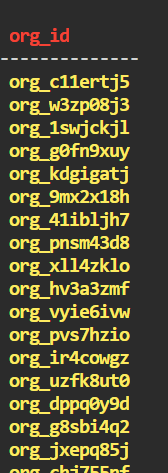

Como son muchas organizaciones, las consultas son a modo demostrativas de solo alguna de ellas

## 1. Costos y requests diarios por org y servicio en un rango de fechas.

In [ ]:
""" use cloud_provider;

SELECT MAX(usage_date) AS max_date
FROM cloud_provider.gold_daily_usage_by_org_service; """

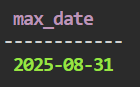

In [ ]:
"""SELECT org_id, org_name, usage_date, resource_service, metric,
       total_cost_usd, total_usage
FROM cloud_provider.gold_daily_usage_by_org_service
WHERE org_id = 'org_c11ertj5'
  AND usage_date >= '2025-08-01'
  AND usage_date <= '2025-08-31';"""


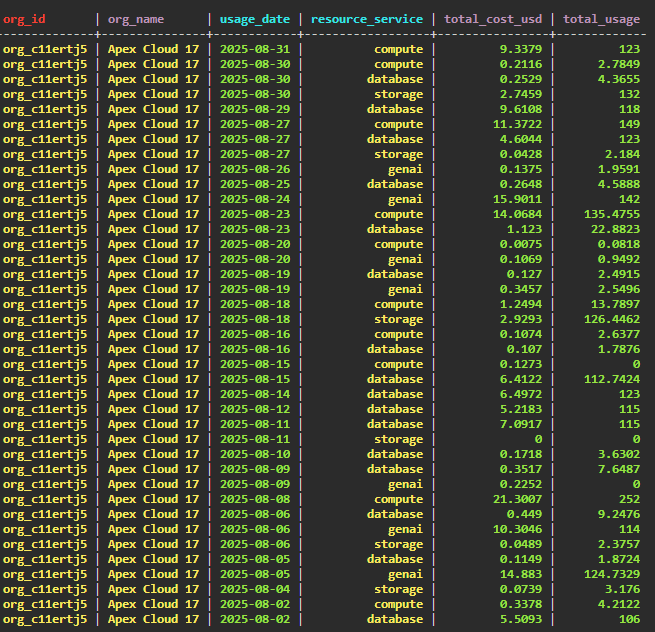

## 2. Top-N servicios por costo acumulado en los últimos 14 días para una organización.

In [ ]:
"""SELECT resource_service, total_cost_usd
FROM cloud_provider.gold_daily_usage_by_org_service
WHERE org_id = 'org_c11ertj5'
  AND usage_date >= '2025-08-17'
ALLOW FILTERING;"""

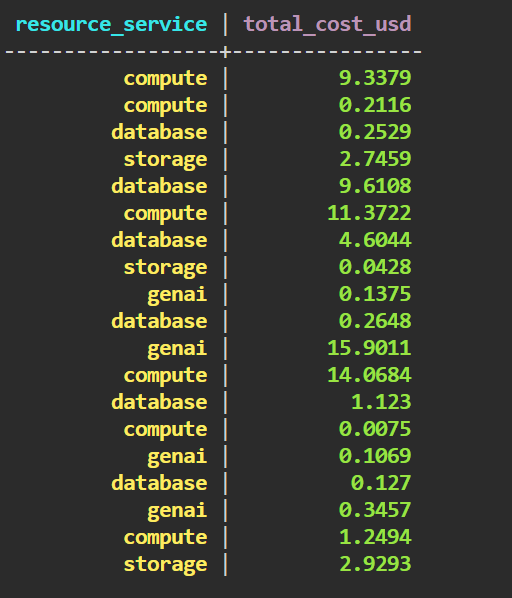

⬇️ *(PARA VERLO AGRUPADO)* ⬇️

In [ ]:
query2 = f"""
SELECT resource_service, total_cost_usd
FROM cloud_provider.gold_daily_usage_by_org_service
WHERE org_id = 'org_c11ertj5'
  AND usage_date >= '2025-08-17'
ALLOW FILTERING;
"""

print(f"- CQL:\n{query2.strip()}\n")

df2 = pd.DataFrame(session.execute(query2))
if df2.empty:
    print(" Sin datos.")
else:
    result = (
        df2.groupby("resource_service")["total_cost_usd"]
        .sum()
        .sort_values(ascending=False)
        .head(5)
        .reset_index()
    )
    print(result.to_markdown(index=False))

## 3. Evolución de tickets críticos y tasa de SLA breach por día (últimos 30 días).

In [ ]:
"""SELECT ticket_date, tickets_count, sla_breach_rate
FROM cloud_provider.gold_support_daily
WHERE org_id = 'org_w3zp08j3'
  AND ticket_date >= '2025-08-01'
  AND severity = 'critical'
ALLOW FILTERING;"""

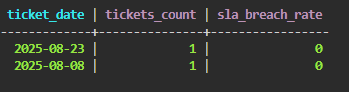

## 4. Revenue mensual con créditos/impuestos aplicados (normalizado a USD).

In [ ]:
"""SELECT billing_month,
       subtotal_usd,
       credits_usd,
       taxes_usd,
       total_revenue_usd
FROM cloud_provider.gold_monthly_revenue
WHERE org_id = 'org_dbdw2pcn'
  AND billing_month >= '2025-01-01'
  AND billing_month <= '2025-12-01';"""

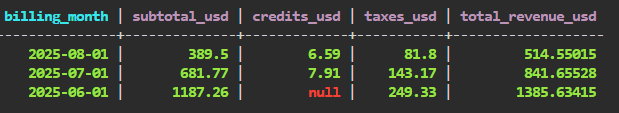

## 5. Tokens GenAI y costo estimado por día (si existen).

In [ ]:
"""SELECT usage_date,
       resource_service,
       total_genai_tokens,
       total_cost_usd
FROM cloud_provider.gold_daily_usage_by_org_service
WHERE org_id = 'org_c11ertj5'
  AND total_genai_tokens > 0
ORDER BY usage_date DESC
ALLOW FILTERING;"""

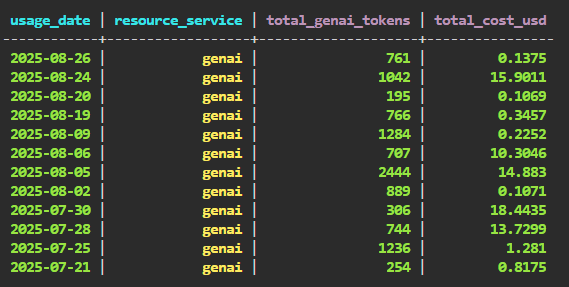